## 1. Bank Account Race Condition

Pada percobaan ini dibuat simulasi rekening bank dengan saldo awal sebesar Rp1.000.000. 
Digunakan 10 thread dan setiap thread melakukan 10.000 kali operasi, yaitu menarik Rp1 
kemudian menyetor kembali Rp1.

Percobaan pertama dilakukan tanpa menggunakan lock untuk melihat apakah terjadi race 
condition. Setelah itu percobaan diulang menggunakan `threading.Lock()` untuk menjaga 
agar proses perubahan saldo dilakukan secara aman.

import threading
import time

saldo = 1_000_000

def transaksi_tanpa_lock():
    global saldo
    
    for _ in range(10_000):
        # Tarik Rp1
        nilai = saldo
        time.sleep(0)
        saldo = nilai - 1
        
        # Setor Rp1
        nilai = saldo
        time.sleep(0)
        saldo = nilai + 1


threads = []

for _ in range(10):
    thread = threading.Thread(target=transaksi_tanpa_lock)
    threads.append(thread)
    thread.start()

for thread in threads:
    thread.join()

print("Saldo awal  : Rp1.000.000")
print("Saldo akhir : Rp{:,.0f}".format(saldo))

### Hasil Tanpa Lock

Pada percobaan tanpa lock, hasil saldo akhir dapat berbeda dari saldo awal. 
Hal ini terjadi karena beberapa thread dapat membaca dan mengubah nilai saldo 
secara bersamaan. Ketika dua thread mengakses saldo pada waktu yang hampir 
bersamaan, perubahan dari salah satu thread dapat tertimpa oleh thread lainnya.

Kondisi tersebut disebut sebagai race condition. Jadi, walaupun setiap thread 
melakukan operasi tarik Rp1 dan setor Rp1, hasil akhirnya belum tentu kembali 
tepat menjadi Rp1.000.000.

In [2]:
saldo = 1_000_000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo
    
    for _ in range(10_000):
        with lock:
            # Tarik Rp1 kemudian setor Rp1
            saldo -= 1
            saldo += 1


threads = []

for _ in range(10):
    thread = threading.Thread(target=transaksi_dengan_lock)
    threads.append(thread)
    thread.start()

for thread in threads:
    thread.join()

print("Saldo awal  : Rp1.000.000")
print("Saldo akhir : Rp{:,.0f}".format(saldo))

Saldo awal  : Rp1.000.000
Saldo akhir : Rp1,000,000


### Perbandingan

Pada percobaan menggunakan `Lock`, saldo akhir kembali menjadi Rp1.000.000. 
`Lock` memastikan bahwa hanya satu thread yang dapat menjalankan bagian kode 
yang mengubah saldo pada satu waktu.

Dengan demikian, race condition dapat dicegah. Perbedaan utama kedua percobaan 
adalah pada penggunaan `threading.Lock()`. Tanpa lock, beberapa thread dapat 
saling bertabrakan ketika mengakses data yang sama, sedangkan dengan lock akses 
terhadap data bersama menjadi lebih teratur dan aman.

## 2. Producer-Consumer dengan Banyak Consumer

Pada percobaan ini digunakan konsep Producer-Consumer menggunakan `queue.Queue`.
Terdapat 1 producer yang menghasilkan data dan 3 consumer yang mengambil data 
dari queue secara bersamaan.

Queue digunakan karena bersifat thread-safe sehingga dapat digunakan oleh 
beberapa thread tanpa harus membuat mekanisme sinkronisasi sendiri. Setelah 
producer selesai memasukkan seluruh data, producer mengirimkan sinyal `None` 
sebanyak jumlah consumer. Setiap consumer akan berhenti ketika menerima 
sinyal `None`.

In [3]:
import threading
import queue
import time

q = queue.Queue()

jumlah_data = 15
jumlah_consumer = 3


def producer():
    for i in range(1, jumlah_data + 1):
        item = f"Data-{i}"
        q.put(item)
        print(f"[Producer] menghasilkan {item}")
        time.sleep(0.1)
    
    # Mengirim sinyal berhenti untuk setiap consumer
    for _ in range(jumlah_consumer):
        q.put(None)
    
    print("[Producer] selesai menghasilkan data")


def consumer(nama):
    while True:
        item = q.get()
        
        if item is None:
            print(f"[{nama}] selesai")
            q.task_done()
            break
        
        print(f"[{nama}] memproses {item}")
        time.sleep(0.2)
        
        q.task_done()


producer_thread = threading.Thread(target=producer)

consumer_threads = []

for i in range(1, jumlah_consumer + 1):
    thread = threading.Thread(
        target=consumer,
        args=(f"Consumer-{i}",)
    )
    consumer_threads.append(thread)


# Menjalankan consumer
for thread in consumer_threads:
    thread.start()

# Menjalankan producer
producer_thread.start()

# Menunggu producer selesai
producer_thread.join()

# Menunggu seluruh pekerjaan queue selesai
q.join()

# Menunggu semua consumer selesai
for thread in consumer_threads:
    thread.join()

print("\nSemua proses producer dan consumer selesai.")

[Producer] menghasilkan Data-1[Consumer-1] memproses Data-1

[Producer] menghasilkan Data-2
[Consumer-2] memproses Data-2
[Producer] menghasilkan Data-3
[Consumer-3] memproses Data-3
[Producer] menghasilkan Data-4[Consumer-1] memproses Data-4

[Producer] menghasilkan Data-5
[Consumer-2] memproses Data-5
[Producer] menghasilkan Data-6
[Consumer-3] memproses Data-6
[Producer] menghasilkan Data-7[Consumer-1] memproses Data-7

[Producer] menghasilkan Data-8
[Consumer-2] memproses Data-8
[Producer] menghasilkan Data-9
[Consumer-3] memproses Data-9
[Producer] menghasilkan Data-10[Consumer-2] memproses Data-10

[Producer] menghasilkan Data-11
[Consumer-1] memproses Data-11
[Producer] menghasilkan Data-12
[Consumer-3] memproses Data-12
[Producer] menghasilkan Data-13[Consumer-2] memproses Data-13

[Producer] menghasilkan Data-14
[Consumer-1] memproses Data-14
[Producer] menghasilkan Data-15[Consumer-3] memproses Data-15

[Producer] selesai menghasilkan data
[Consumer-2] selesai
[Consumer-1] se

### Penjelasan

Pada program ini hanya terdapat satu producer yang bertugas menghasilkan data.
Data tersebut dimasukkan ke dalam queue menggunakan `q.put()`.

Tiga consumer berjalan secara bersamaan dan mengambil data menggunakan 
`q.get()`. Karena terdapat tiga consumer, pekerjaan yang dihasilkan producer 
dapat dibagi kepada ketiga consumer tersebut.

Ketika producer selesai menghasilkan seluruh data, producer memasukkan `None`
sebanyak tiga kali ke dalam queue. Masing-masing `None` digunakan sebagai 
sinyal bahwa satu consumer harus berhenti.

Penggunaan `q.join()` digunakan untuk memastikan semua pekerjaan yang berada 
di dalam queue sudah selesai diproses sebelum program berakhir.

## 3. Eksperimen ThreadPoolExecutor

Pada eksperimen ini dilakukan simulasi proses pengunduhan 50 file. 
Pengujian dilakukan menggunakan `ThreadPoolExecutor` dengan jumlah 
`max_workers` sebesar 2, 4, 8, dan 16.

Tujuan percobaan adalah mengetahui pengaruh jumlah thread terhadap waktu 
eksekusi. Hasil pengukuran kemudian dibuat dalam bentuk grafik untuk melihat 
perubahan waktu eksekusi.

In [4]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import time
import matplotlib.pyplot as plt


# Simulasi proses download sebuah file
def download_file(nama_file):
    time.sleep(0.2)
    return nama_file


# Membuat daftar 50 file
daftar_file = [f"file_{i}.txt" for i in range(1, 51)]


hasil_waktu = {}

for max_workers in [2, 4, 8, 16]:
    
    start = time.perf_counter()
    
    hasil = []
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        
        future_ke_file = {
            executor.submit(download_file, file): file
            for file in daftar_file
        }
        
        for future in as_completed(future_ke_file):
            hasil_file = future.result()
            hasil.append(hasil_file)
    
    end = time.perf_counter()
    
    waktu = end - start
    hasil_waktu[max_workers] = waktu
    
    print(f"max_workers = {max_workers}")
    print(f"Jumlah file = {len(hasil)}")
    print(f"Waktu eksekusi = {waktu:.2f} detik")
    print("-" * 40)

max_workers = 2
Jumlah file = 50
Waktu eksekusi = 5.02 detik
----------------------------------------
max_workers = 4
Jumlah file = 50
Waktu eksekusi = 2.61 detik
----------------------------------------
max_workers = 8
Jumlah file = 50
Waktu eksekusi = 1.40 detik
----------------------------------------
max_workers = 16
Jumlah file = 50
Waktu eksekusi = 0.80 detik
----------------------------------------


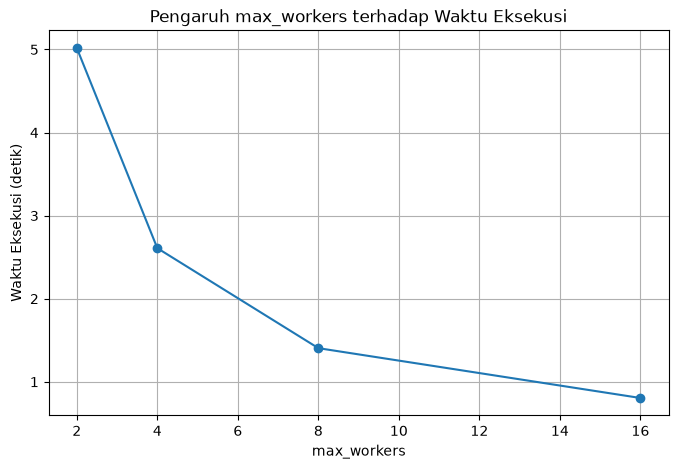

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(hasil_waktu.keys()),
    list(hasil_waktu.values()),
    marker='o'
)

plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title("Pengaruh max_workers terhadap Waktu Eksekusi")
plt.grid(True)

plt.show()

### Analisis Hasil

Berdasarkan hasil percobaan, penambahan jumlah `max_workers` pada awalnya 
dapat mengurangi waktu eksekusi karena lebih banyak file dapat diproses secara 
bersamaan.

Ketika jumlah worker dinaikkan dari 2 menjadi 4 dan 8, proses biasanya menjadi 
lebih cepat karena semakin banyak pekerjaan yang dapat berjalan secara paralel.

Namun, menambah `max_workers` secara terus-menerus tidak selalu membuat proses 
semakin cepat. Pada jumlah worker yang terlalu banyak, terdapat overhead untuk 
mengatur thread, perpindahan antar-thread, serta persaingan menggunakan sumber 
daya sistem.

Oleh karena itu terdapat titik jenuh. Setelah mencapai jumlah worker tertentu, 
penambahan worker hanya memberikan sedikit peningkatan atau bahkan dapat 
membuat waktu eksekusi menjadi lebih lama.

Pada percobaan ini, hasil waktu dapat sedikit berbeda setiap kali program 
dijalankan karena dipengaruhi oleh kondisi komputer dan proses penjadwalan 
thread oleh sistem operasi.